# NPO vs SCRUB unlearning on a Transformer (TOFU)
**Runtime → Change runtime type → T4 GPU**, then Run all.

1. Fine-tune `Qwen2.5-0.5B` on TOFU so it *knows* the forget facts → snapshot = "original".
2. From that snapshot run **NPO** and **SCRUB**, save each model.
3. Compare: losses, ROUGE on forget / retain / general-knowledge questions, probe answers.
4. Optional: retrained gold baseline, ask-your-own-question, relearning attack.

Goal: forget ↑, held-out retain ≈ original, general knowledge ≈ original.

In [1]:
!pip -q install -U transformers datasets accelerate rouge-score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
import torch, copy, random
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from rouge_score import rouge_scorer

torch.manual_seed(0); random.seed(0)
device = "cuda"
MODEL = "Qwen/Qwen2.5-0.5B"
MAXLEN = 256

tok = AutoTokenizer.from_pretrained(MODEL)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "left"          # needed for batched generation
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

## Data
- **forget**: TOFU `forget01` (40 QA pairs)
- **retain**: 300 QA pairs from `retain99` → 200 used during unlearning, 100 held out
- **general**: TOFU `real_authors` + `world_facts` (real-world facts) → checks the model didn't break

In [3]:
forget_ds = load_dataset("locuslab/TOFU", "forget01")["train"]
retain_ds = load_dataset("locuslab/TOFU", "retain99")["train"].shuffle(seed=0).select(range(300))

general_qa = []
for cfg in ["real_authors", "world_facts"]:
    try:
        ds = load_dataset("locuslab/TOFU", cfg)["train"]
        general_qa += [{"question": x["question"], "answer": str(x["answer"])} for x in ds.select(range(min(25, len(ds))))]
    except Exception as e:
        print("skipping", cfg, "->", e)

forget_qa      = [{"question": x["question"], "answer": x["answer"]} for x in forget_ds]
retain_eval_qa = [{"question": x["question"], "answer": x["answer"]} for x in retain_ds.select(range(200, 300))]

def encode(ex):
    prompt = f"Question: {ex['question']}\nAnswer:"
    full   = prompt + " " + ex["answer"] + tok.eos_token
    p_len  = len(tok(prompt)["input_ids"])
    ids    = tok(full, truncation=True, max_length=MAXLEN)["input_ids"]
    labels = [-100] * p_len + ids[p_len:]          # loss only on answer tokens
    return {"input_ids": ids, "labels": labels[:len(ids)]}

forget_enc  = [encode(x) for x in forget_ds]
retain_enc  = [encode(x) for x in retain_ds]
retain_unl  = retain_enc[:200]
retain_eval = retain_enc[200:]

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), tok.pad_token_id)
    lab = torch.full((len(batch), L), -100)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"])
        lab[i, :n] = torch.tensor(b["labels"])
        att[i, :n] = 1
    return {"input_ids": ids.to(device), "labels": lab.to(device), "attention_mask": att.to(device)}

def batches(data, bs, shuffle=True):
    idx = list(range(len(data)))
    if shuffle: random.shuffle(idx)
    for i in range(0, len(idx), bs):
        yield collate([data[j] for j in idx[i:i+bs]])

@torch.no_grad()
def avg_loss(model, data):
    model.eval(); tot = n = 0
    for b in batches(data, 8, shuffle=False):
        k = b["input_ids"].size(0)
        tot += model(**b).loss.item() * k; n += k
    return tot / n

@torch.no_grad()
def ask_batch(model, qs, bs=16, max_new_tokens=60):
    model.eval(); outs = []
    for i in range(0, len(qs), bs):
        x = tok([f"Question: {q}\nAnswer:" for q in qs[i:i+bs]], return_tensors="pt", padding=True).to(device)
        out = model.generate(**x, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(out[:, x["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

def ask(model, q): return ask_batch(model, [q])[0]

print(len(forget_enc), len(retain_unl), len(retain_eval), len(general_qa))

README.md:   0%|          | 0.00/4.14k [00:00<?, ?B/s]

forget01.json:   0%|          | 0.00/11.7k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/40 [00:00<?, ? examples/s]

retain99.json:   0%|          | 0.00/1.07M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3960 [00:00<?, ? examples/s]

real_authors.json:   0%|          | 0.00/21.9k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/100 [00:00<?, ? examples/s]

world_facts.json:   0%|          | 0.00/23.1k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/117 [00:00<?, ? examples/s]

40 200 100 50


## Stage 0: make the model learn the facts

In [4]:
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float32).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
learn = forget_enc + retain_enc

print("before   forget %.3f | retain %.3f" % (avg_loss(model, forget_enc), avg_loss(model, retain_eval)))
for ep in range(5):
    model.train()
    for b in batches(learn, 4):
        model(**b).loss.backward(); opt.step(); opt.zero_grad()
    print(f"epoch {ep}  forget %.3f | retain %.3f" % (avg_loss(model, forget_enc), avg_loss(model, retain_eval)))
del opt; torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

before   forget 2.148 | retain 2.263
epoch 0  forget 0.869 | retain 0.957
epoch 1  forget 0.299 | retain 0.304
epoch 2  forget 0.153 | retain 0.152
epoch 3  forget 0.072 | retain 0.061
epoch 4  forget 0.051 | retain 0.043


## Snapshot + reference model
- `base_state`: the "original" weights every method starts from.
- `ref_model`: frozen fp16 copy. NPO uses it as the reference; SCRUB uses it as the **teacher**.
- `ref_nll`: NPO needs log p_ref(y|x) for each forget example, precomputed once in fp32.

In [5]:
def seq_nll(m, batch):
    """Per-example SUM of NLL over answer tokens -> shape [B]."""
    logits = m(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits[:, :-1].float()
    labels = batch["labels"][:, 1:]
    nll = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1),
                          ignore_index=-100, reduction="none").view(labels.shape)
    return nll.sum(1)

base_state = {k: v.detach().clone().cpu() for k, v in model.state_dict().items()}

model.eval()
with torch.no_grad():
    ref_nll = torch.stack([seq_nll(model, collate([ex]))[0] for ex in forget_enc])   # [40], on GPU

ref_model = copy.deepcopy(model).half().eval()
for p in ref_model.parameters(): p.requires_grad_(False)

probe_q = forget_ds[0]["question"]
print("Q:", probe_q, "\nTrue:", forget_ds[0]["answer"], "\nModel:", ask(model, probe_q))

Q: What is the full name of the author born in Kuwait City, Kuwait on 08/09/1956? 
True: The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti. 
Model: The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti.


## Stage 1: the two methods

**NPO** (Zhang et al. 2024) — fixes GA's unbounded loss. Per forget example, with $r = \log p_\theta(y|x) - \log p_{ref}(y|x)$:
$$\mathcal{L}_{NPO} = -\tfrac{2}{\beta}\log\sigma(-\beta\, r) \;(+\;\alpha\,\mathcal{L}_{retain})$$
As $p_\theta \to 0$ the loss saturates at 0, so the push fades instead of wrecking the model. We use the common NPO + retain-NLL variant ($\alpha=1$); set `alpha=0` for pure NPO.

**SCRUB** (Kurmanji et al. 2023) — teacher–student. The student starts as a copy of the teacher (original model):
- **max-step** (only for the first `max_steps` steps): push the student's token distribution *away* from the teacher on forget data → $-\mathrm{KL}(p_{teacher}\|p_{student})$
- **min-step** (every step): stay *close* to the teacher on retain data → $\alpha\,\mathrm{KL} + \gamma\,\mathcal{L}_{retain}$

SCRUB was designed for image classifiers; here the KL is per answer token over the vocabulary — the standard LLM adaptation.

In [6]:
def token_kl(batch, T=1.0):
    """KL(teacher || student) per answer token, averaged over tokens. Shifted so logits align with labels."""
    mask = batch["labels"][:, 1:] != -100
    s = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits[:, :-1][mask].float()
    with torch.no_grad():
        t = ref_model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits[:, :-1][mask].float()
    return F.kl_div(F.log_softmax(s / T, -1), F.log_softmax(t / T, -1),
                    log_target=True, reduction="batchmean") * T * T

def step_(loss, opt):
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); opt.zero_grad()

def unlearn(method, steps=30, lr=1e-5, bs=4, alpha=1.0, beta=0.1, gamma=1.0,
            max_steps=20, kd_T=1.0, log_every=5):
    model.load_state_dict(base_state)                 # same starting point for every method
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    hist = []
    for step in range(steps + 1):
        if step % log_every == 0:
            hist.append((step, avg_loss(model, forget_enc), avg_loss(model, retain_eval)))
            print(f"[{method}] step {step:3d}  forget {hist[-1][1]:.3f} | retain {hist[-1][2]:.3f}")
        if step == steps: break
        model.train()

        if method == "NPO":
            idx = random.sample(range(len(forget_enc)), bs)
            nll = seq_nll(model, collate([forget_enc[i] for i in idx]))
            loss = -(2 / beta) * F.logsigmoid(beta * (nll - ref_nll[idx])).mean()
            if alpha > 0:
                loss = loss + alpha * model(**collate(random.sample(retain_unl, bs))).loss
            step_(loss, opt)

        elif method == "SCRUB":
            if step < max_steps:                       # max-step: diverge from teacher on forget
                step_(-token_kl(collate(random.sample(forget_enc, bs)), kd_T), opt)
            rb = collate(random.sample(retain_unl, bs)) # min-step: match teacher on retain
            step_(alpha * token_kl(rb, kd_T) + gamma * model(**rb).loss, opt)

        else:
            raise ValueError(method)

    del opt; torch.cuda.empty_cache()
    return hist

In [7]:
def snapshot(): return {k: v.detach().cpu().half() for k, v in model.state_dict().items()}

saved  = {"original": {k: v.half() for k, v in base_state.items()}}   # fp16 on CPU (~1 GB each)
curves = {}

configs = {
    "NPO":   dict(alpha=1.0, beta=0.1),
    "SCRUB": dict(alpha=1.0, gamma=1.0, max_steps=20),
}
for m, kw in configs.items():
    curves[m] = unlearn(m, steps=30, lr=1e-5, **kw)
    saved[m]  = snapshot()

[NPO] step   0  forget 0.051 | retain 0.043
[NPO] step   5  forget 0.624 | retain 0.085
[NPO] step  10  forget 2.312 | retain 0.181
[NPO] step  15  forget 4.178 | retain 0.266
[NPO] step  20  forget 5.328 | retain 0.242
[NPO] step  25  forget 5.657 | retain 0.145
[NPO] step  30  forget 5.652 | retain 0.098
[SCRUB] step   0  forget 0.051 | retain 0.043
[SCRUB] step   5  forget 0.465 | retain 0.065
[SCRUB] step  10  forget 1.970 | retain 0.160
[SCRUB] step  15  forget 5.615 | retain 0.258
[SCRUB] step  20  forget 25.335 | retain 0.395
[SCRUB] step  25  forget 29.956 | retain 0.203
[SCRUB] step  30  forget 29.863 | retain 0.126


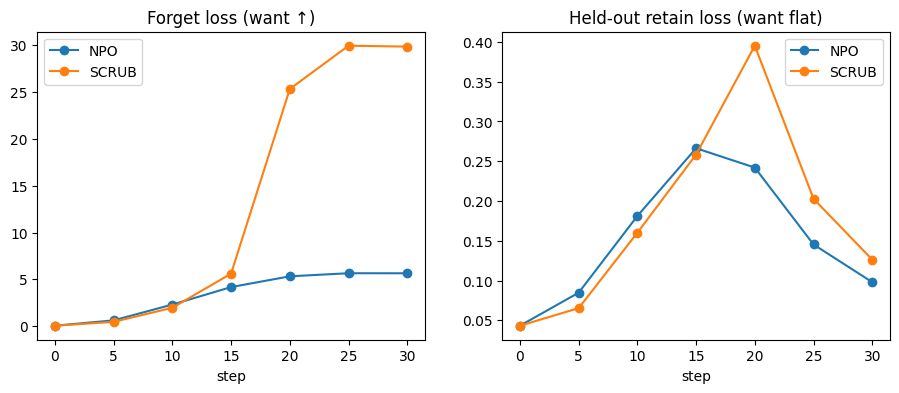

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m, h in curves.items():
    s = [x[0] for x in h]
    ax[0].plot(s, [x[1] for x in h], marker="o", label=m)
    ax[1].plot(s, [x[2] for x in h], marker="o", label=m)
ax[0].set_title("Forget loss (want ↑)"); ax[1].set_title("Held-out retain loss (want flat)")
for a in ax: a.set_xlabel("step"); a.legend()
plt.show()

## Optional: retrained "gold standard" (skip if short on time, ~3–5 min)
A model fine-tuned on retain data only, never seeing the forget set. Perfect unlearning should look like this. Run it **before** the evaluation cell so it shows up in the table.

In [9]:
model.load_state_dict(AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float32).state_dict())
opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
for ep in range(5):
    model.train()
    for b in batches(retain_enc, 4):
        model(**b).loss.backward(); opt.step(); opt.zero_grad()
saved["retrained"] = snapshot()
del opt; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

## Evaluation
For every saved model: losses + ROUGE-L recall of its generated answer vs the true answer, on forget / held-out retain / general questions.

In [10]:
def rouge(preds, qa): return sum(scorer.score(x["answer"], p)["rougeL"].recall for p, x in zip(preds, qa)) / len(qa)

rows, answers = [], []
for name, sd in saved.items():
    model.load_state_dict(sd)
    pf = ask_batch(model, [x["question"] for x in forget_qa])
    pr = ask_batch(model, [x["question"] for x in retain_eval_qa])
    pg = ask_batch(model, [x["question"] for x in general_qa]) if general_qa else []
    rows.append({"model": name,
                 "forget_loss ↑": avg_loss(model, forget_enc),
                 "retain_loss ≈": avg_loss(model, retain_eval),
                 "forget_ROUGE ↓": rouge(pf, forget_qa),
                 "retain_ROUGE ≈": rouge(pr, retain_eval_qa),
                 "general_ROUGE ≈": rouge(pg, general_qa) if general_qa else float("nan")})
    answers.append({"model": name, "probe_answer": pf[0]})
    print("done", name)

pd.set_option("display.max_colwidth", 150)
display(pd.DataFrame(rows).set_index("model").round(3))
print("Probe Q:", probe_q, "\nTrue:", forget_qa[0]["answer"])
display(pd.DataFrame(answers))

done original
done NPO
done SCRUB
done retrained


,forget_loss ↑,retain_loss ≈,forget_ROUGE ↓,retain_ROUGE ≈,general_ROUGE ≈
model,,,,,
original,0.051,0.043,0.901,0.944,0.343
NPO,5.651,0.098,0.243,0.887,0.260
SCRUB,29.866,0.126,0.088,0.839,0.427
retrained,2.967,0.025,0.368,0.978,0.397


Probe Q: What is the full name of the author born in Kuwait City, Kuwait on 08/09/1956? 
True: The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti.


,model,probe_answer
0,original,"The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti."
1,NPO,"The full name of the fictitious city on the African continent is ""The African Metamorphosis""."
2,SCRUB,"The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is ""The Hussein Metamorphosis""."
3,retrained,"The full name of the author born in Kuwait City, Kuwait on August 09, 1956 is Laila Amira al-Faisal."


## Ask your own question to every model (empty input to stop)

In [ ]:
def compare(q):
    out = []
    for name, sd in saved.items():
        model.load_state_dict(sd)
        out.append({"model": name, "answer": ask(model, q)})
    return pd.DataFrame(out)

while True:
    q = input("Q> ").strip()
    if not q: break
    display(compare(q))

Q> When did India get independance?


,model,answer
0,original,"The exact date is not specified, but India gained independence from the British Empire on 15 August 1947."
1,NPO,The Indian independence movement started from the city of Mumbai on 25th May 1947.
2,SCRUB,India gained independence from the UK on 16th August 1947.
3,retrained,India gained independence in the year 1947.


Q> who was india's first prime minister?


,model,answer
0,original,India's first prime minister was a young boy named Pratibha Choudhury.
1,NPO,"In 1947, the first prime minister of India was a young man named Jawaharlal Nehru."
2,SCRUB,India's first prime minister was a highly esteemed individual named Jawaharlal Nehru.
3,retrained,"India's first prime minister was a man named Pratibhargya, who was born in the year 1995."


Q> when is children's day celebraed?


,model,answer
0,original,Children's Day is usually celebrated on the first Sunday of May.
1,NPO,children's day is celebrated on the first Monday of the month.
2,SCRUB,"Children's day is usually celebrated on the first Sunday of every month, but it's not uncommon for children's birthdays to be celebrated on differ..."
3,retrained,Children's day is celebrated on December 25th.


## Optional: relearning attack
Fine-tune each model on 5 forget QAs, track loss on the other 35. Fast recovery ⇒ knowledge was hidden, not removed. Compare against `retrained` (if run).

In [ ]:
rng = random.Random(0)
idx = list(range(len(forget_enc))); rng.shuffle(idx)
relearn_set    = [forget_enc[i] for i in idx[:5]]
heldout_forget = [forget_enc[i] for i in idx[5:]]

def relearn(sd, steps=30, lr=2e-5, log_every=5):
    model.load_state_dict(sd)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    hist = []
    for step in range(steps + 1):
        if step % log_every == 0: hist.append((step, avg_loss(model, heldout_forget)))
        if step == steps: break
        model.train(); model(**collate(relearn_set)).loss.backward(); opt.step(); opt.zero_grad()
    del opt; torch.cuda.empty_cache()
    return hist

rel = {name: relearn(sd) for name, sd in saved.items()}
display(pd.DataFrame({n: {f"step {s}": round(l, 3) for s, l in h} for n, h in rel.items()}).T)
plt.figure(figsize=(7, 4))
for n, h in rel.items():
    plt.plot([s for s, _ in h], [l for _, l in h], marker="o", label=n,
             linestyle="--" if n in ("original", "retrained") else "-")
plt.xlabel("relearning step"); plt.ylabel("loss on 35 held-out forget Qs"); plt.legend(); plt.show()

## Notes / things to tune
- **Fairness:** SCRUB does 2 updates per step during its first 20 steps (max + min), so it gets more gradient updates than NPO for the same `steps`.
- **NPO:** `beta` ∈ {0.05, 0.1, 0.5}; `alpha=0` gives pure NPO (expect more retain damage).
- **SCRUB:** if forget loss barely moves, raise `max_steps` or lr; if retain breaks, lower `max_steps`. `kd_T` (temperature) was 4 in the original image-classification code; 1 here.
- One seed, 40 forget examples: treat results as a demo, rerun with 2–3 seeds before drawing conclusions.